# Week 3: Forward and Backward Selection, PCR, and PLSR
**Rupal Paliwal, Mod C, Semester 1**

**Dataset:** Movies Box Office 2000 to 2024 (Kaggle), the same 5,000 films used in Weeks 1, 2, and 4.

**Question:** Out of 32 features, which ones does a model really need to predict worldwide revenue? I try two stepwise methods (forward and backward selection) and two dimension reduction methods (principal component regression and partial least squares regression), and compare what they choose.

**Part 1** uses the box office data. **Part 2** adds the other two project datasets, MovieLens 20M and the 4 Services Streaming catalogs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score

## 1. Load and prepare the data

Same preparation as Weeks 2 and 4: rating converted from text like `'8.217/10'`, vote count logged, genres as 0/1 columns, the top 10 languages as 0/1 columns (English is the reference), and rows with missing or zero ratings dropped. The money columns other than the target are left out because worldwide gross is domestic plus foreign, so they would leak the answer.

**Target:** `log($Worldwide)`.

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')

data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

# Numeric features
X = pd.DataFrame({
    'log_votes': np.log1p(data['Vote_Count']),
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

# Genres (multi hot) and top 10 languages (English is the reference)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
y = np.log(data['$Worldwide'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (3842, 32) | Test: (961, 32)


## 2. Forward selection

Start with no features. At each step, try adding every remaining feature, keep the one that gives the best 5 fold CV R², and repeat. Using **CV R² on held out folds** (not training R²) is what stops the method from simply adding everything: training R² always goes up with more features, but CV R² stops improving once extra features only fit noise.

In [3]:
def cv_r2(cols):
    return cross_val_score(LinearRegression(), X_train[cols], y_train, cv=kf, scoring='r2').mean()

selected, remaining, forward = [], list(X.columns), []
while remaining:
    scores = {f: cv_r2(selected + [f]) for f in remaining}
    best = max(scores, key=scores.get)
    selected.append(best)
    remaining.remove(best)
    forward.append({'step': len(selected), 'added': best, 'CV_R2': round(scores[best], 4)})

forward = pd.DataFrame(forward)
forward.head(12)

,step,added,CV_R2
0,1,log_votes,0.3981
1,2,lang_zh,0.4659
2,3,genre_Adventure,0.4882
3,4,lang_fr,0.5033
4,5,genre_Drama,0.5093
5,6,lang_ja,0.5145
6,7,genre_Family,0.5192
7,8,lang_it,0.5233
8,9,lang_es,0.5274
9,10,genre_Horror,0.5313


In [4]:
best_k = forward.loc[forward['CV_R2'].idxmax(), 'step']
print('Best number of features (forward):', best_k, '| CV R2:', forward['CV_R2'].max())

Best number of features (forward): 26 | CV R2: 0.548


## 3. Backward selection

Start with all 32 features. At each step, remove the feature whose removal gives the best CV R², and repeat.

In [5]:
current = list(X.columns)
backward = [{'n_features': len(current), 'removed': None, 'CV_R2': round(cv_r2(current), 4)}]
while len(current) > 1:
    scores = {f: cv_r2([c for c in current if c != f]) for f in current}
    worst = max(scores, key=scores.get)
    current.remove(worst)
    backward.append({'n_features': len(current), 'removed': worst, 'CV_R2': round(scores[worst], 4)})

backward = pd.DataFrame(backward)
best_b = backward.loc[backward['CV_R2'].idxmax()]
print('Best number of features (backward):', best_b['n_features'], '| CV R2:', best_b['CV_R2'])
print('First 8 features removed:', list(backward['removed'][1:9]))

Best number of features (backward): 26 | CV R2: 0.548
First 8 features removed: ['genre_War', 'genre_Comedy', 'genre_Mystery', 'lang_other', 'genre_History', 'genre_Science Fiction', 'genre_Animation', 'genre_TV Movie']


### Do the two methods agree?

In [6]:
last_8_backward = [current[0]] + list(backward['removed'][::-1][:7])
first_8_forward = list(forward['added'][:8])
print('Forward, first 8 added:   ', first_8_forward)
print('Backward, last 8 standing:', last_8_backward)
print('Same set?', set(first_8_forward) == set(last_8_backward))

Forward, first 8 added:    ['log_votes', 'lang_zh', 'genre_Adventure', 'lang_fr', 'genre_Drama', 'lang_ja', 'genre_Family', 'lang_it']
Backward, last 8 standing: ['log_votes', 'lang_zh', 'genre_Adventure', 'lang_fr', 'genre_Drama', 'lang_ja', 'genre_Family', 'lang_it']
Same set? True


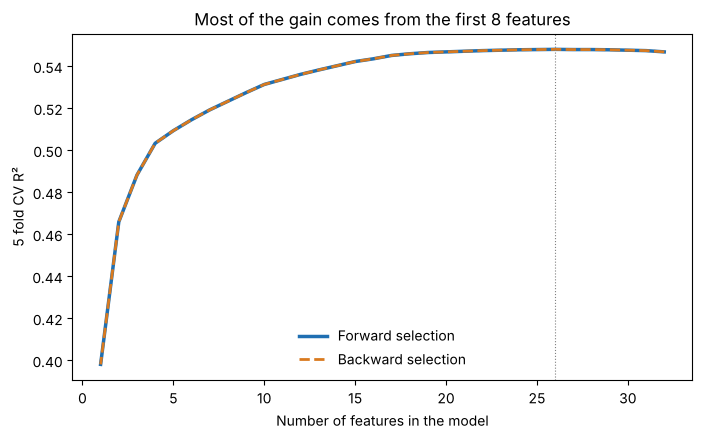

In [7]:
plt.figure(figsize=(8, 4.5))
plt.plot(forward['step'], forward['CV_R2'], color='#1f6fb2', linewidth=2.5, label='Forward selection')
plt.plot(backward['n_features'], backward['CV_R2'], color='#d97a1f', linewidth=2, linestyle='--', label='Backward selection')
plt.axvline(best_k, color='grey', linewidth=0.8, linestyle=':')
plt.xlabel('Number of features in the model')
plt.ylabel('5 fold CV R²')
plt.title('Most of the gain comes from the first 8 features')
plt.legend(frameon=False)
plt.show()

The two lines lie exactly on top of each other: forward and backward selection found the same model at every size.

Test set check of the selected models (only now do I touch the test set):

In [8]:
def test_r2(cols):
    return round(r2_score(y_test, LinearRegression().fit(X_train[cols], y_train).predict(X_test[cols])), 4)

pd.DataFrame([
    {'model': 'All 32 features', 'features': 32, 'test_R2': test_r2(list(X.columns))},
    {'model': f'Forward selection (best CV, {best_k})', 'features': best_k, 'test_R2': test_r2(list(forward['added'][:best_k]))},
    {'model': 'First 8 from forward selection', 'features': 8, 'test_R2': test_r2(first_8_forward)},
    {'model': 'log_votes only', 'features': 1, 'test_R2': test_r2(['log_votes'])},
])

,model,features,test_R2
0,All 32 features,32,0.5256
1,"Forward selection (best CV, 26)",26,0.5250
2,First 8 from forward selection,8,0.4974
3,log_votes only,1,0.3775


## 4. Principal component regression (PCR)

PCR standardizes the features, runs PCA, and regresses revenue on the first *k* principal components. I choose *k* by CV. Standardizing first matters: without it, `year` (variance about 51) would dominate PCA purely because of its units.

In [9]:
ks = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 25, 32]
pcr_cv, pls_cv = [], []
for k in ks:
    pcr = make_pipeline(StandardScaler(), PCA(n_components=k), LinearRegression())
    pls = make_pipeline(StandardScaler(), PLSRegression(n_components=k, scale=False))
    pcr_cv.append(cross_val_score(pcr, X_train, y_train, cv=kf, scoring='r2').mean())
    pls_cv.append(cross_val_score(pls, X_train, y_train, cv=kf, scoring='r2').mean())

comp = pd.DataFrame({'components': ks, 'PCR_CV_R2': np.round(pcr_cv, 4), 'PLSR_CV_R2': np.round(pls_cv, 4)})
comp

,components,PCR_CV_R2,PLSR_CV_R2
0,1,0.0369,0.4241
1,2,0.1586,0.4889
2,3,0.1586,0.5116
3,4,0.2999,0.5304
4,5,0.3147,0.5449
5,6,0.3149,0.5466
6,8,0.3148,0.5468
7,10,0.3319,0.5468
8,15,0.3713,0.5468
9,20,0.4345,0.5468


PCR needs almost every component before it catches up. To see why, look at what the first component is made of:

In [10]:
pca = make_pipeline(StandardScaler(), PCA()).fit(X_train)[-1]
print('Variance explained by first 5 PCs:', pca.explained_variance_ratio_[:5].round(3))
pd.Series(pca.components_[0], index=X.columns).sort_values(key=abs, ascending=False).head(6).round(2)

Variance explained by first 5 PCs: [0.082 0.073 0.057 0.05  0.045]


genre_Family       0.45
genre_Animation    0.44
genre_Adventure    0.38
genre_Fantasy      0.33
genre_Thriller    -0.27
genre_Drama       -0.26
dtype: float64

PC1 is a "family / animation / adventure vs. thriller" genre axis. It captures the most *variance* in the features (8%), but that variation has almost nothing to do with revenue (CV R² 0.04 with one component). Vote count, the feature that actually drives revenue, is spread across several later components.

## 5. Partial least squares regression (PLSR)

PLSR also builds components, but it picks directions that have high covariance with the **target**, not just high variance in the features.

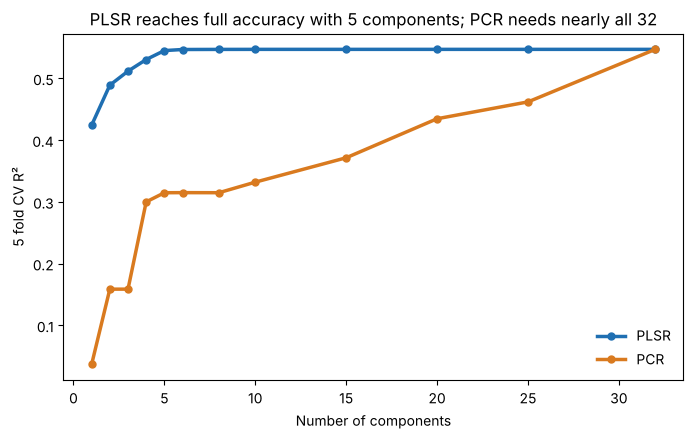

In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(ks, pls_cv, color='#1f6fb2', linewidth=2.5, marker='o', markersize=5, label='PLSR')
plt.plot(ks, pcr_cv, color='#d97a1f', linewidth=2.5, marker='o', markersize=5, label='PCR')
plt.xlabel('Number of components')
plt.ylabel('5 fold CV R²')
plt.title('PLSR reaches full accuracy with 5 components; PCR needs nearly all 32')
plt.legend(frameon=False)
plt.show()

In [12]:
pls5 = make_pipeline(StandardScaler(), PLSRegression(n_components=5, scale=False)).fit(X_train, y_train)
pcr5 = make_pipeline(StandardScaler(), PCA(n_components=5), LinearRegression()).fit(X_train, y_train)
print('Test R2, PLSR with 5 components:', round(r2_score(y_test, pls5.predict(X_test).ravel()), 4))
print('Test R2, PCR with 5 components: ', round(r2_score(y_test, pcr5.predict(X_test)), 4))

Test R2, PLSR with 5 components: 0.5226
Test R2, PCR with 5 components:  0.3446


# Part 2: All Three Project Datasets

My project has three datasets: the box office data used above, **MovieLens 20M** (user ratings, tags, and the tag genome), and the **4 Services Streaming** catalogs (Netflix, Prime Video, Hulu, Disney+). `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb` joins them by cleaned title and release year and saves `combined_films.csv`.

MovieLens 20M ends in 2015, so Part 2 uses the **films released 2000 to 2015 that matched MovieLens**. To see what the extra datasets add, every model is fit twice on exactly the same films and split:
- **Box office only**: the same 32 features as Part 1
- **All three datasets**: those 32 plus 7 new ones: MovieLens rating count (log), MovieLens average rating, MovieLens tag count (log), and 0/1 flags for Netflix, Prime Video, Hulu, and Disney+

In [13]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = np.log(sub['$Worldwide'])                     # log worldwide gross
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


## P2.1 Forward selection with all three datasets

In [14]:
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42)
def cv_r2_3(cols):
    return cross_val_score(LinearRegression(), XB.loc[tr3, cols], y3[tr3], cv=kf, scoring='r2').mean()

selected3, remaining3, forward3 = [], list(XB.columns), []
while remaining3:
    scores = {f: cv_r2_3(selected3 + [f]) for f in remaining3}
    best = max(scores, key=scores.get)
    selected3.append(best); remaining3.remove(best)
    forward3.append({'step': len(selected3), 'added': best, 'CV_R2': round(scores[best], 4)})
forward3 = pd.DataFrame(forward3)
best3 = forward3.loc[forward3['CV_R2'].idxmax()]
print('Best model:', best3['step'], 'features, CV R2', best3['CV_R2'])
forward3.head(10)

Best model: 25 features, CV R2 0.6442


,step,added,CV_R2
0,1,log_votes,0.5626
1,2,genre_Adventure,0.5895
2,3,genre_Family,0.6001
3,4,lang_zh,0.6079
4,5,year,0.6142
5,6,ml_mean_rating,0.6186
6,7,ml_log_ratings,0.6254
7,8,lang_ko,0.6295
8,9,genre_Crime,0.6319
9,10,genre_Action,0.6341


## P2.2 PCR vs. PLSR on the MovieLens tag genome

The tag genome describes each film with 1,128 scores, a natural case for dimension reduction. Here I use **only** the genome tags (no vote counts) to see how much of revenue the film's content description explains.

In [15]:
# MovieLens tag genome: 1,128 relevance scores (0 to 1) per film, saved by the data prep notebook
genome = pd.read_csv('genome_features.csv', index_col=0)
has_genome = sub['ml_movieId'].astype(int).isin(genome.index)
gsub = sub[has_genome]
G = genome.loc[gsub['ml_movieId'].astype(int)].set_index(gsub.index)
print('Films with tag genome scores:', len(gsub), '| genome tags:', G.shape[1])

Films with tag genome scores: 2179 | genome tags: 1128


In [16]:
y_g = y3[gsub.index]
trg, teg = train_test_split(G.index, test_size=0.2, random_state=42)
kg = [1, 2, 5, 10, 20, 50, 100]
pcr_g, pls_g = [], []
for k in kg:
    pcr_g.append(cross_val_score(make_pipeline(StandardScaler(), PCA(k), LinearRegression()), G.loc[trg], y_g[trg], cv=kf, scoring='r2').mean())
    pls_g.append(cross_val_score(make_pipeline(StandardScaler(), PLSRegression(k, scale=False)), G.loc[trg], y_g[trg], cv=kf, scoring='r2').mean())
pd.DataFrame({'components': kg, 'PCR_CV_R2': np.round(pcr_g, 4), 'PLSR_CV_R2': np.round(pls_g, 4)})

,components,PCR_CV_R2,PLSR_CV_R2
0,1,0.0135,0.3801
1,2,0.2617,0.4478
2,5,0.3421,0.6405
3,10,0.3987,0.6634
4,20,0.4562,0.5787
5,50,0.5863,0.0761
6,100,0.6267,-0.4657


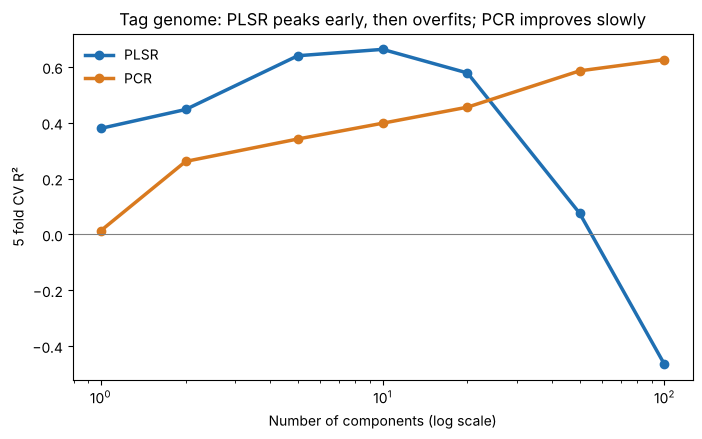

In [17]:
plt.figure(figsize=(8, 4.5))
plt.plot(kg, pls_g, color='#1f6fb2', linewidth=2.5, marker='o', label='PLSR')
plt.plot(kg, pcr_g, color='#d97a1f', linewidth=2.5, marker='o', label='PCR')
plt.xscale('log'); plt.axhline(0, color='grey', linewidth=0.8)
plt.xlabel('Number of components (log scale)'); plt.ylabel('5 fold CV R²')
plt.title('Tag genome: PLSR peaks early, then overfits; PCR improves slowly')
plt.legend(frameon=False); plt.show()

In [18]:
pca_g = make_pipeline(StandardScaler(), PCA(2)).fit(G.loc[trg])[-1]
print('Variance explained by PC1 and PC2:', pca_g.explained_variance_ratio_.round(3))
for i in range(2):
    load = pd.Series(pca_g.components_[i], index=G.columns).sort_values()
    print(f'PC{i+1} low end: ', list(load.index[:4]))
    print(f'PC{i+1} high end:', list(load.index[-4:]))
pls10 = make_pipeline(StandardScaler(), PLSRegression(10, scale=False)).fit(G.loc[trg], y_g[trg])
print('Test R2, PLSR with 10 components (genome tags only):', round(r2_score(y_g[teg], pls10.predict(G.loc[teg]).ravel()), 4))

Variance explained by PC1 and PC2: [0.142 0.062]
PC1 low end:  ['tag_predictable', "tag_so bad it's funny", 'tag_bad plot', 'tag_silly']
PC1 high end: ['tag_social commentary', 'tag_talky', 'tag_movielens top pick', 'tag_interesting']
PC2 low end:  ['tag_relationships', 'tag_women', 'tag_shopping', 'tag_marriage']
PC2 high end: ['tag_dynamic cgi action', 'tag_special effects', 'tag_big budget', 'tag_technology']


Test R2, PLSR with 10 components (genome tags only): 0.6551


## 6. Conclusions

**Forward and backward selection agreed completely.** Both chose the same 26 features (CV R² 0.548), and at every model size they found the same set. The features they drop first are genres that add nothing: War, Comedy, Mystery, History, Science Fiction, Animation, TV Movie, and the "other language" group. Dropping them costs nothing on the test set (0.525 vs. 0.526).

**A small core does most of the work.** The first 8 features (log votes, Chinese, Adventure, French, Drama, Japanese, Family, Italian) reach a CV R² of 0.523, about 95% of the best model. Vote count alone reaches 0.398. This is almost the same short list lasso kept in Week 2 at λ = 0.1 (6 of its 7 features are here; only Action differs). Three different methods pointing at the same features makes me much more confident these are the real drivers.

**PCR failed, PLSR worked.** With 5 components, PLSR reaches a test R² of **0.523** but PCR only **0.345**. PCA picks the directions where the *features* vary most, and here PC1 is a genre axis (Family, Animation, and Adventure vs. Thriller and Drama) that has almost nothing to do with revenue (CV R² 0.04). PLSR picks directions that move with *revenue*, so its first component already reaches CV R² 0.42. This is exactly the lesson's warning: a high variance direction is not necessarily a useful one.

**How I avoided overfitting:** every selection step was scored with 5 fold CV, not training R², and the number of features or components was chosen where CV R² peaked. The test set was used only once at the end, and test results matched CV closely.

**A caution:** the p values of a model chosen by stepwise selection can't be trusted, because the procedure tried hundreds of feature sets and kept the best one. That is why I compare models by CV and test R² here instead of p values.

**Part 2 (all three datasets).** Forward selection on the 39 combined features still picks log votes first, and the MovieLens average rating and rating count both enter within the first seven steps, ahead of most genres. On the tag genome alone, PLSR reaches its best CV R² with about 10 components and then overfits sharply as more components chase noise, while PCR improves slowly and needs far more components. The first principal component of the genome is a **quality** axis ("interesting", "MovieLens top pick" vs. "predictable", "bad plot") that explains the most variance but almost none of revenue, while the second is a **blockbuster** axis ("big budget", "special effects" vs. "relationships"). This repeats the main project finding in a completely different dataset: scale and reach drive revenue, quality does not. Strikingly, PLSR on the genome tags alone, with no vote counts at all, explains about 65% of the variation in log revenue on the test films.

### Think About It

**In forward selection with four features, which combinations do you miss if you add them in the order x1, x2, x3, then x4?** There are 15 possible non empty combinations. Forward selection tries all 4 single features, then {x1,x2}, {x1,x3}, {x1,x4}, then {x1,x2,x3}, {x1,x2,x4}, then all four, which is 10 sets. It never tries these 5: **{x2,x3}, {x2,x4}, {x3,x4}, {x1,x3,x4}, and {x2,x3,x4}**.

**Describe a situation where a feature (or principal component) has low variance but is still important for prediction.** My data has a real example. Only about 6% of films are in Chinese, so `lang_zh` has a variance of about 0.05, compared with about 51 for `year`. Without standardizing, PCA would rank it near the bottom and PCR would throw it away. But it is the **second** feature forward selection picks, because Chinese films earn far more than their vote counts suggest. A rare feature with a big effect is easy for a variance based method to miss.